## Coverage calculations

All files on farm in `/home/ctbrown/scratch3/2026-pancoding-core

In [1]:
# base checkout of workflow directory is here:
BASE='/home/ctbrown/scratch3/2026-pancoding-core'


In [2]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import scipy
import math
import sourmash
import collections

import seaborn as sns
from matplotlib.legend_handler import HandlerTuple

In [3]:
NAMES = [ x.strip() for x in open(BASE+'/inputs.branchwater/names.list') ]
print(f'loaded {len(NAMES)} species names')

NAMES.sort()
NAMES

loaded 16 species names


['s__Bariatricus sp004560705',
 's__Colivicinus sp002299675',
 's__Cryptobacteroides sp000432655',
 's__Cryptobacteroides sp000434935',
 's__Cryptobacteroides sp034089285',
 's__Cryptobacteroides sp900546925',
 's__Fimisoma sp002320005',
 's__Floccifex porci',
 's__JAFBIX01 sp021531895',
 's__Lactobacillus amylovorus',
 's__Mogibacterium_A kristiansenii',
 's__Ornithospirochaeta sp022785155',
 's__Prevotella sp000434975',
 's__Prevotella sp002251295',
 's__Sodaliphilus sp004557565',
 's__UBA2868 sp004552595']

## Load all the extract k-mer stats for all species

In [4]:
species_kmers_df = pl.read_csv('../outputs.isect/3216_kmer_stats.csv')
species_kmers_df

species,metag,intersect_bp,weighted_bp
str,str,i64,i64
"""s__Bariatricus sp004560705""","""ERR3212028""",384000,708000
"""s__Bariatricus sp004560705""","""ERR3211889""",474000,821000
"""s__Bariatricus sp004560705""","""SRR8960468""",448000,880000
"""s__Bariatricus sp004560705""","""SRR8960622""",1014000,5675000
"""s__Bariatricus sp004560705""","""SRR11126389""",295000,428000
…,…,…,…
"""s__UBA2868 sp004552595""","""SRR11125751""",144000,669000
"""s__UBA2868 sp004552595""","""SRR11183692""",1484000,20458000
"""s__UBA2868 sp004552595""","""ERR3211805""",423000,2616000


In [5]:
assert set(species_kmers_df['species']) == set(NAMES)

## Build a basic coverage curve function

$$y = G (1 - e^{(-Cx)})$$

G is the genome size, C is the coverage exponent.

In [6]:
def coverage_curve(x, G, C):
    return G*(1 - np.exp(-C*x))

Text(0.5, 1.0, 'example coverage curve')

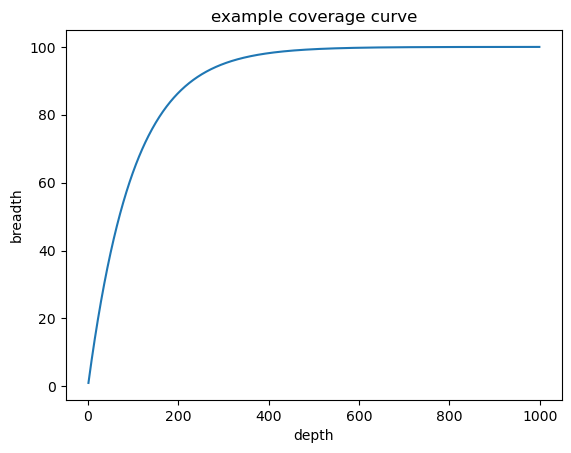

In [7]:
x = np.arange(1, 1000)
y = [ coverage_curve(xx, 100, .01) for xx in x ]
plt.plot(x, y)
plt.xlabel('depth')
plt.ylabel('breadth')
plt.title("example coverage curve")

## Build a fit function that takes weighted bp (x) and intersection (y) and fits to a coverage curve

In [8]:
def do_fit(contain_df, *, fn=coverage_curve, p0=None):
    "Fit to given function, which takes two parameters, G and C. Return fit values & params."
    if p0 is None:
        p0 = (max(contain_df['weighted_bp']), .001)
    popt, pcov = scipy.optimize.curve_fit(fn, contain_df['weighted_bp'], contain_df['intersect_bp'], p0)
    G, C = popt

    y = np.asarray(contain_df['weighted_bp'])
    yfit = coverage_curve(y, G, C)

    # residual sum of squares
    ss_res = np.sum((y - yfit) ** 2)
    # total sum of squares
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    # r-squared
    r2 = 1 - (ss_res / ss_tot)

    return yfit, (G, C), r2

fitting for: s__Bariatricus sp004560705
fit params for s__Bariatricus sp004560705: G=1122462 C=5.630997507331577e-07; r2=-0.106


/group/datalabgrp/ctbrown/2025-grist-annie/.snakemake/conda/ab4c18c32e39b7f9ba11a10bc8c18bcf_/lib/python3.12/site-packages/polars/series/series.py:1571: RuntimeWarning: overflow encountered in exp
  lambda out: ufunc(*args, out=out, dtype=dtype_char, **kwargs),
/group/datalabgrp/ctbrown/2025-grist-annie/.snakemake/conda/ab4c18c32e39b7f9ba11a10bc8c18bcf_/lib/python3.12/site-packages/polars/series/series.py:1571: RuntimeWarning: overflow encountered in multiply
  lambda out: ufunc(*args, out=out, dtype=dtype_char, **kwargs),


Text(0.5, 1.0, 's__Bariatricus sp004560705')

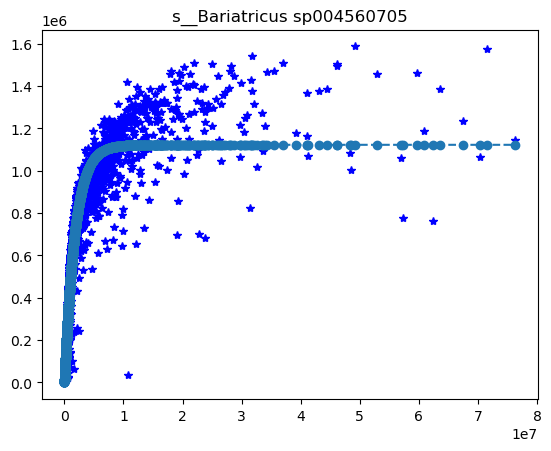

In [9]:
# test fit function!
name = NAMES[0]
print('fitting for:', NAMES[0])
species_df = species_kmers_df.filter(pl.col("species") == NAMES[0]).sort(by='weighted_bp')

yfit, (G, C), r2 = do_fit(species_df)
print(f"fit params for {name}: G={G:.0f} C={C}; r2={r2:.3f}")
plt.plot(species_df['weighted_bp'], species_df['intersect_bp'], 'b*')
plt.plot(species_df['weighted_bp'], yfit, 'o--')
plt.title(name)

## Run fit function for all species, and record parameters.

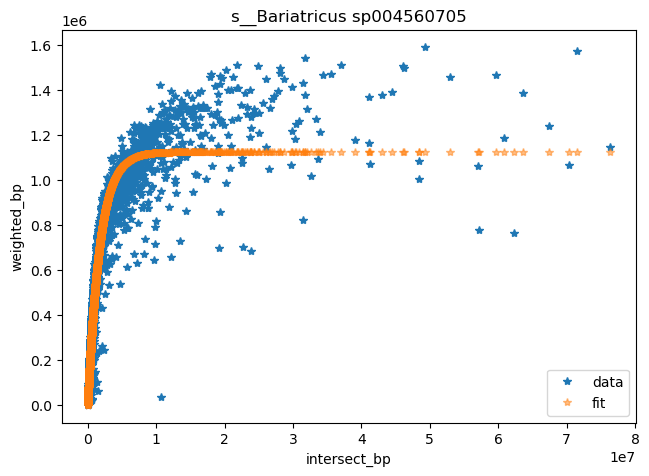

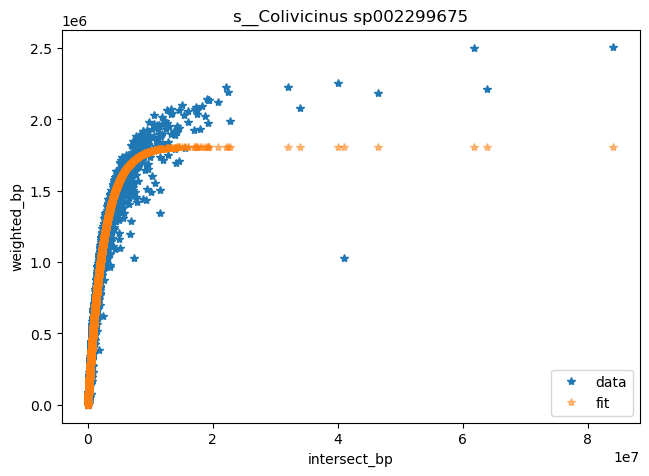

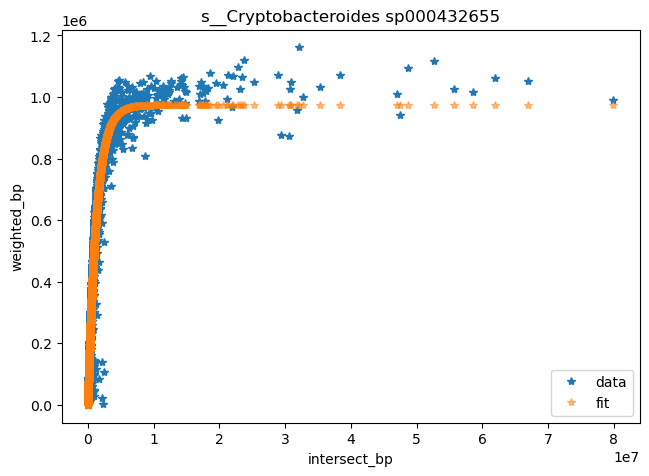

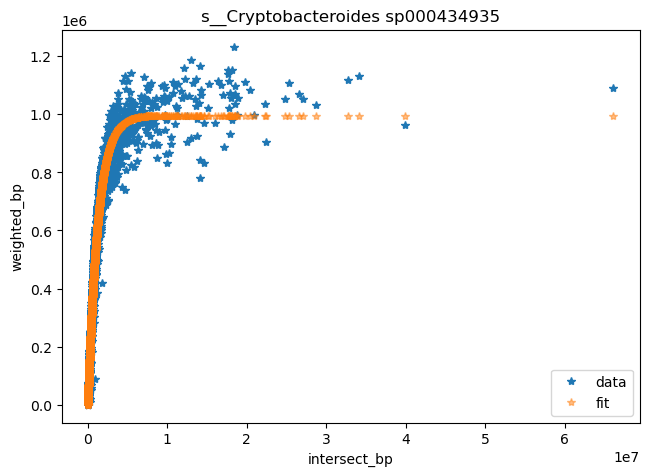

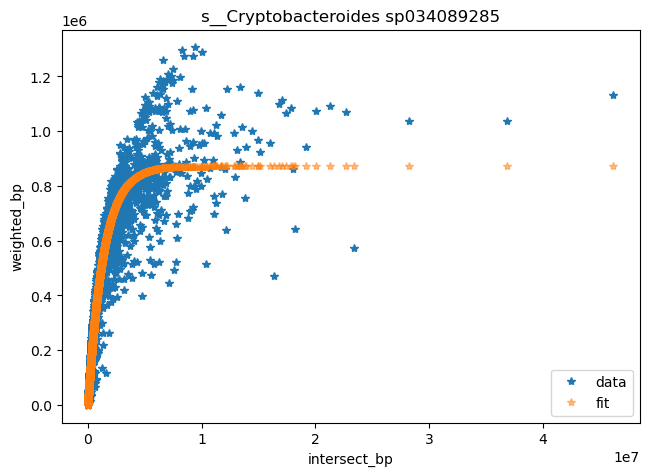

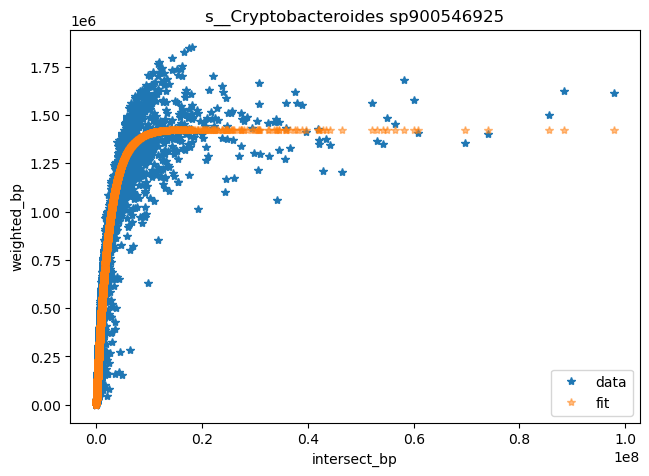

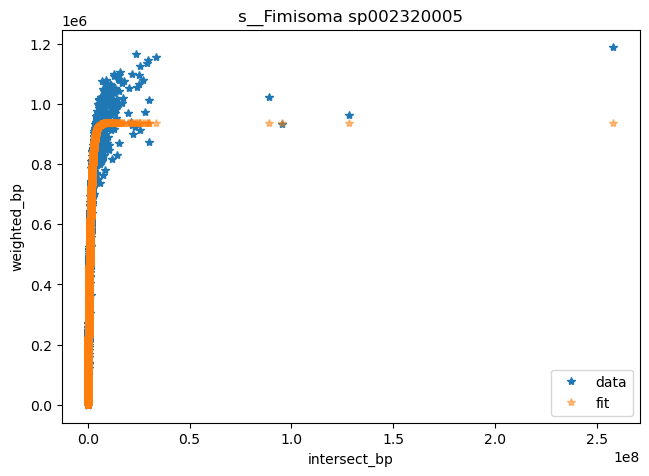

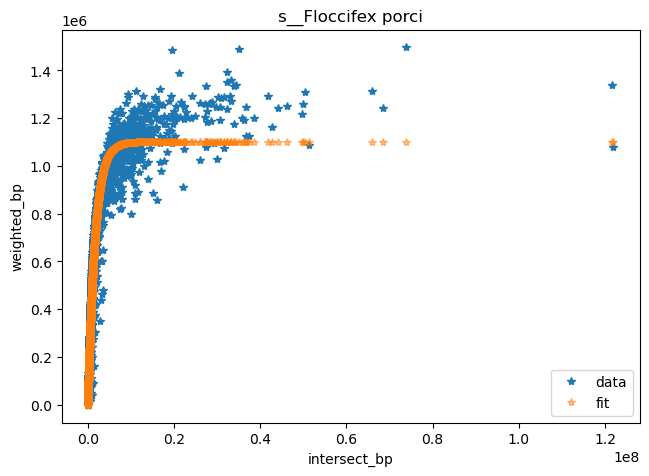

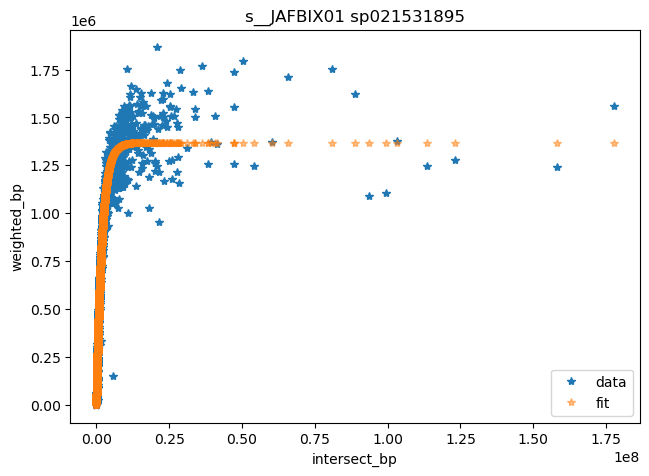

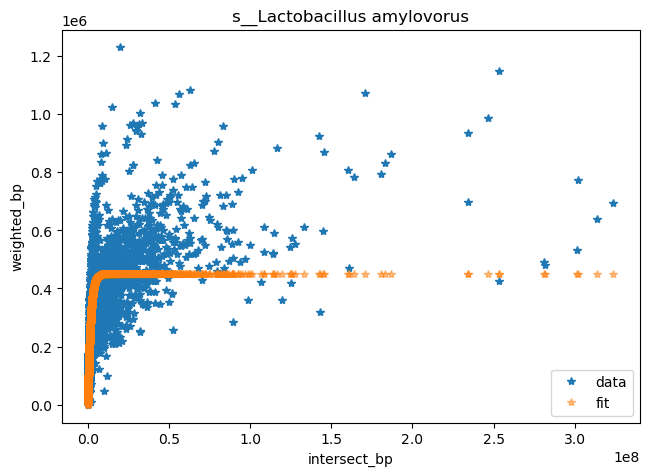

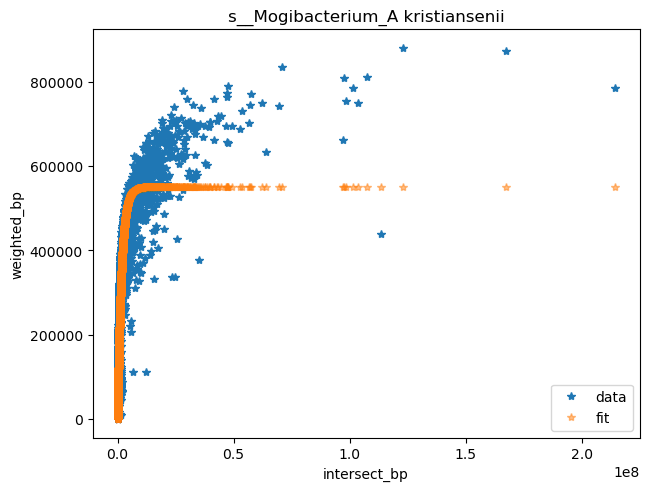

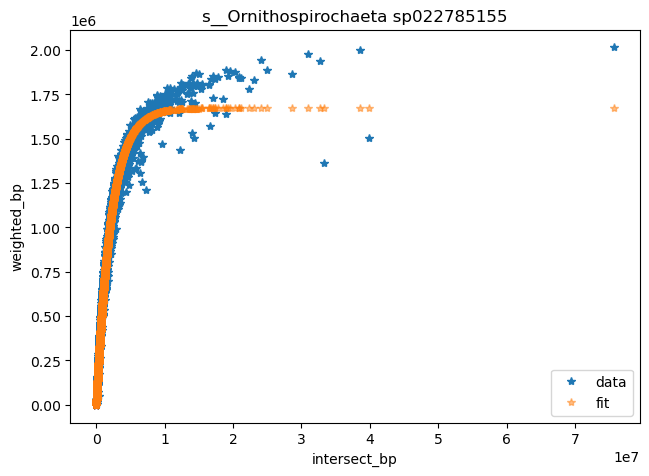

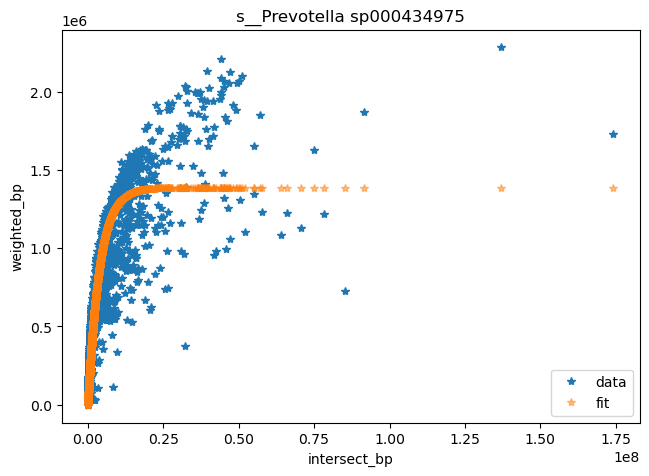

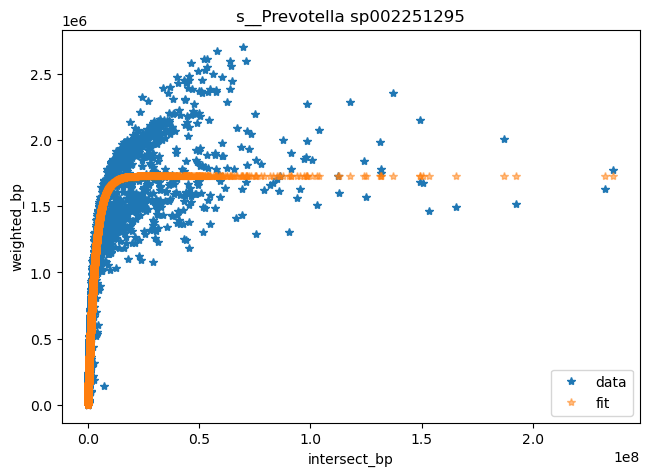

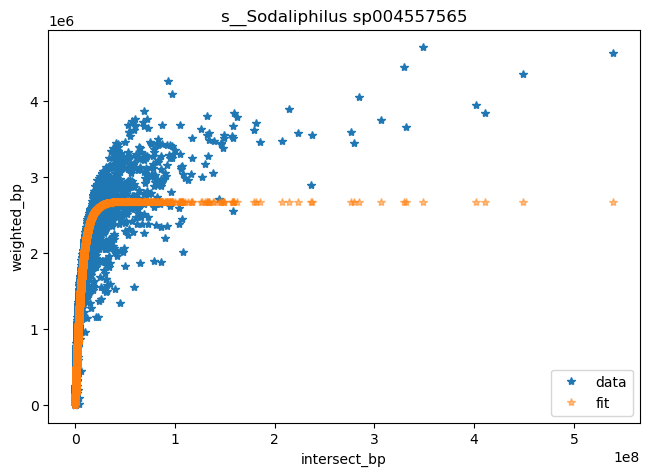

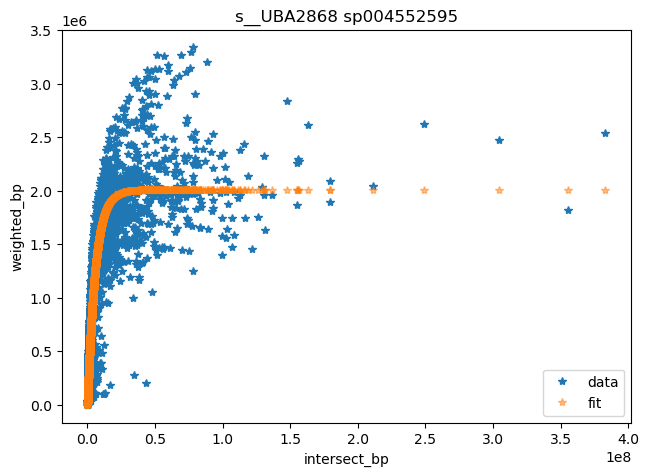

In [10]:
params_d = {}
params_df = []

for name in NAMES:
    species_df = species_kmers_df.filter(pl.col("species") == name)
    yfit, params, r2 = do_fit(species_df)
    (GSIZE, CEXP) = params
    params_d[name] = (GSIZE, CEXP, r2)
    med = np.median(species_df['weighted_bp'] / GSIZE)
    q25 = np.percentile(species_df['weighted_bp'] / GSIZE, .25)
    num_metag = len(species_df.filter(pl.col("intersect_bp") > 20000))
#    print(f"{name:<50} {GSIZE / 1e6:.1f} Mbp    {med:.2f}        {EXP}")
    params_df.append(dict(name=name, med=med, gsize=GSIZE, exp=CEXP, num_metag=num_metag, r2=r2, q25=q25))

    plt.plot(species_df['weighted_bp'], species_df['intersect_bp'], '*', label='data')
    plt.plot(species_df['weighted_bp'], yfit, '*', alpha=0.5, label='fit')
    plt.tight_layout()

    plt.title(name)
    plt.xlabel('intersect_bp')
    plt.ylabel('weighted_bp')
    plt.legend(loc='lower right')

    #plt.xlim(0, 3)
    #plt.ylim(0, 1.5)
    plt.show()

params_df = pl.DataFrame(params_df)

In [11]:
params_df

name,med,gsize,exp,num_metag,r2,q25
str,f64,f64,f64,i64,f64,f64
"""s__Bariatricus sp004560705""",0.99647,1.1225e6,5.6310e-7,3104,-0.105606,0.000891
"""s__Colivicinus sp002299675""",0.570231,1.8098e6,3.9640e-7,3080,0.021378,0.000553
"""s__Cryptobacteroides sp0004326…",0.888045,972924.183579,7.7234e-7,3060,-0.042912,0.0
"""s__Cryptobacteroides sp0004349…",0.449003,995539.784701,7.9033e-7,3065,0.012635,0.000038
"""s__Cryptobacteroides sp0340892…",0.889412,871362.33177,7.2795e-7,3112,-0.090291,0.0
…,…,…,…,…,…,…
"""s__Ornithospirochaeta sp022785…",0.538726,1.6725e6,4.5941e-7,3067,0.029123,0.0
"""s__Prevotella sp000434975""",0.419134,1.3862e6,2.5729e-7,3043,-0.088774,0.001443
"""s__Prevotella sp002251295""",1.144072,1.7254e6,3.1260e-7,3112,-0.164246,0.001159


In [12]:
print("species                                     med cov       q25           gsize")
for row in params_df.sort(by='med').iter_rows(named=True):
    name, med, gsize, num_metag, r2, q25 = row["name"], row["med"], row["gsize"], row["num_metag"], row["r2"], row['q25']
    print(f"{name:<45} {med:<10.2f}  {q25:<10.4f}   {gsize/1e6:.1f}Mbp     in {num_metag}    {r2:.3f}")

species                                     med cov       q25           gsize
s__Prevotella sp000434975                     0.42        0.0014       1.4Mbp     in 3043    -0.089
s__Cryptobacteroides sp000434935              0.45        0.0000       1.0Mbp     in 3065    0.013
s__JAFBIX01 sp021531895                       0.46        0.0007       1.4Mbp     in 3118    -0.019
s__Ornithospirochaeta sp022785155             0.54        0.0000       1.7Mbp     in 3067    0.029
s__Colivicinus sp002299675                    0.57        0.0006       1.8Mbp     in 3080    0.021
s__Fimisoma sp002320005                       0.73        0.0000       0.9Mbp     in 3126    -0.019
s__Floccifex porci                            0.77        0.0000       1.1Mbp     in 3111    -0.080
s__Cryptobacteroides sp000432655              0.89        0.0000       1.0Mbp     in 3060    -0.043
s__Cryptobacteroides sp034089285              0.89        0.0000       0.9Mbp     in 3112    -0.090
s__Bariatricus sp00456070

## Update with a new fit function that we have an estimated genome size

We can now adjust 'x' by the estimated size of the (pan) genome, for each species.

Read through [the inStrain docs](https://instrain.readthedocs.io/en/latest/important_concepts.html) for some interesting context -
the coverage parameter should be ~0.88 for a full genome. Here we are using pancoding species-specific sketches so who knows :)

In [13]:
# try with adjusted coverage, where we divide 'x' by tbe estimated genome size
params2_d = {}
for name in NAMES:
    species_df = species_kmers_df.filter(pl.col("species") == name)
    GSIZE, EXP, r2 = params_d[name]

    def adj_coverage_curve(x, c, e):
        return c*(1 - np.exp(-e*x/GSIZE))

    p0 = (max(species_df['weighted_bp']), 0.9)
    _, params2, _ = do_fit(species_df, fn=adj_coverage_curve, p0=p0)
    NORM, EXP2 = params2
    print(f"{name:<50} {NORM:<10.0f} {EXP2:2f}")
    params2_d[name] = params2

s__Bariatricus sp004560705                         1122457    0.632066
s__Colivicinus sp002299675                         1809788    0.717398
s__Cryptobacteroides sp000432655                   972924     0.751428
s__Cryptobacteroides sp000434935                   995540     0.786803
s__Cryptobacteroides sp034089285                   871360     0.634310
s__Cryptobacteroides sp900546925                   1424050    0.600551
s__Fimisoma sp002320005                            936218     0.768032
s__Floccifex porci                                 1099410    0.670087
s__JAFBIX01 sp021531895                            1366689    0.711746
s__Lactobacillus amylovorus                        451254     0.267758
s__Mogibacterium_A kristiansenii                   549994     0.322602
s__Ornithospirochaeta sp022785155                  1672462    0.768354
s__Prevotella sp000434975                          1386163    0.356689
s__Prevotella sp002251295                          1725420    0.539359
s__Sod

In [14]:
# use the new information to estimate breadth and depth for every row, and then add into data frame.
adj_df = []

for row in species_kmers_df.iter_rows(named=True):
    species = row["species"]
    metag = row["metag"]
    intersect_bp = row["intersect_bp"]
    weighted_bp = row["weighted_bp"]
    GSIZE, EXP, r2 = params_d[species]
    fit_breadth = intersect_bp / GSIZE
    fit_depth = weighted_bp / GSIZE
    curve_breadth = coverage_curve(weighted_bp, GSIZE, EXP) / GSIZE
    adj_df.append(dict(species=species, metag=metag, fit_breadth=fit_breadth, fit_depth=fit_depth, curve_breadth=curve_breadth))

adj_df = pl.DataFrame(adj_df)
join_df = species_kmers_df.join(adj_df, on=['species', 'metag'], how='inner')
join_df

species,metag,intersect_bp,weighted_bp,fit_breadth,fit_depth,curve_breadth
str,str,i64,i64,f64,f64,f64
"""s__Bariatricus sp004560705""","""ERR3212028""",384000,708000,0.342105,0.630756,0.328791
"""s__Bariatricus sp004560705""","""ERR3211889""",474000,821000,0.422286,0.731428,0.37017
"""s__Bariatricus sp004560705""","""SRR8960468""",448000,880000,0.399123,0.783991,0.390751
"""s__Bariatricus sp004560705""","""SRR8960622""",1014000,5675000,0.903371,5.055851,0.959058
"""s__Bariatricus sp004560705""","""SRR11126389""",295000,428000,0.262815,0.381305,0.214164
…,…,…,…,…,…,…
"""s__UBA2868 sp004552595""","""SRR11125751""",144000,669000,0.0718,0.333573,0.1081
"""s__UBA2868 sp004552595""","""SRR11183692""",1484000,20458000,0.739944,10.200655,0.969754
"""s__UBA2868 sp004552595""","""ERR3211805""",423000,2616000,0.210914,1.304375,0.360676


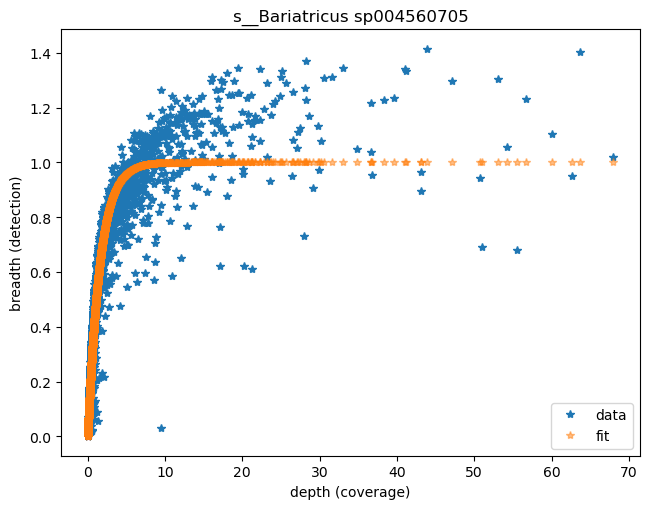

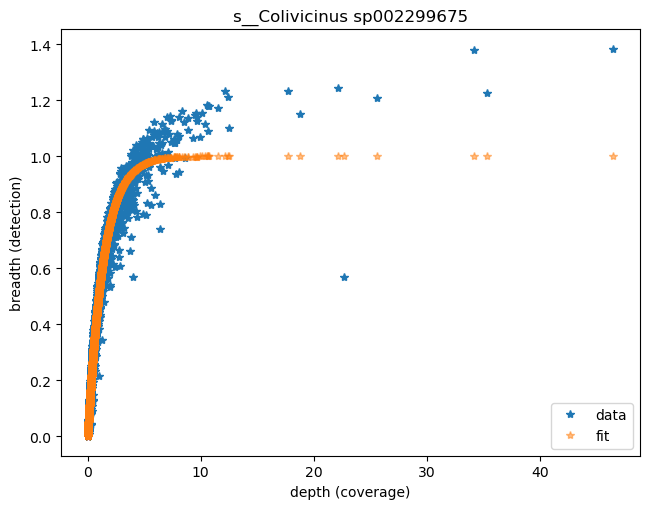

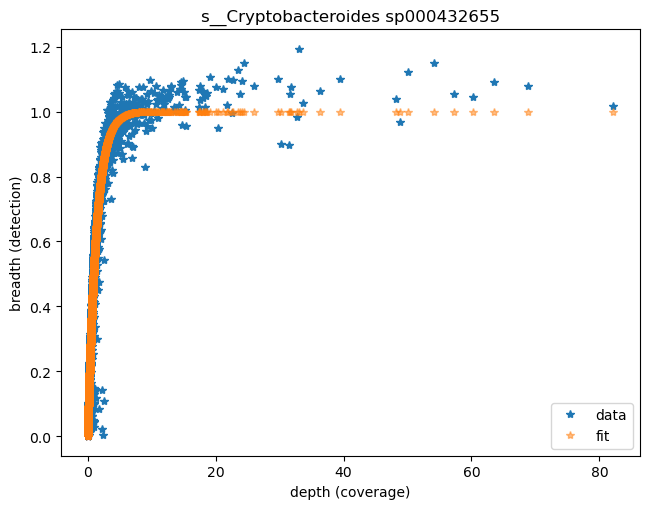

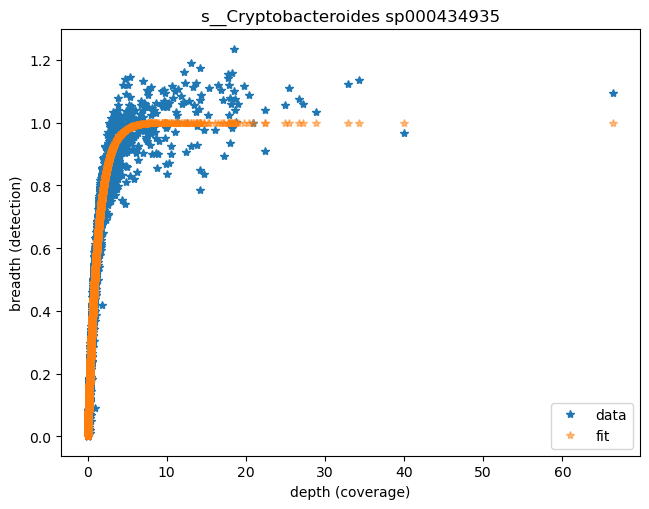

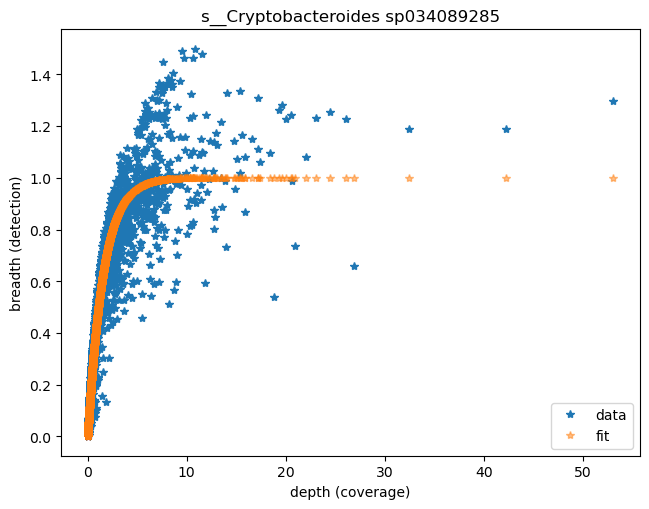

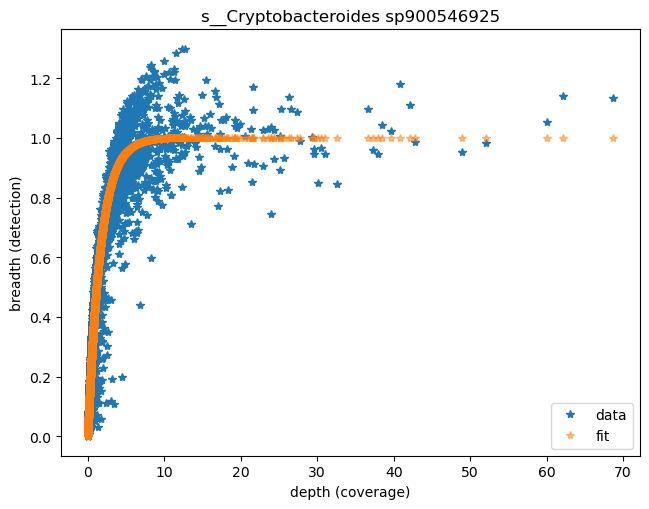

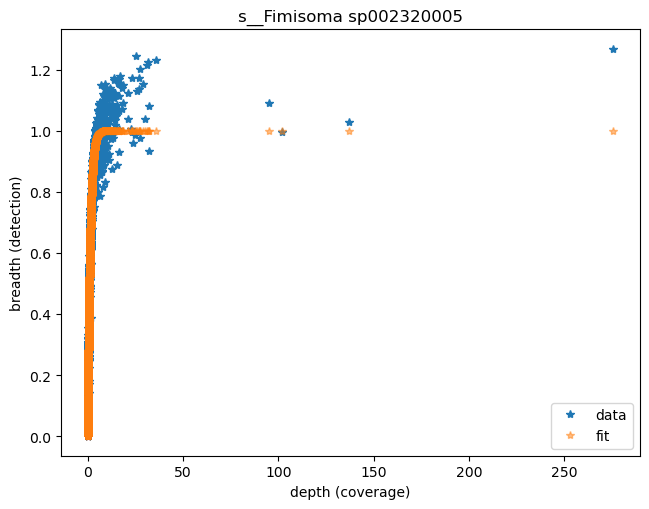

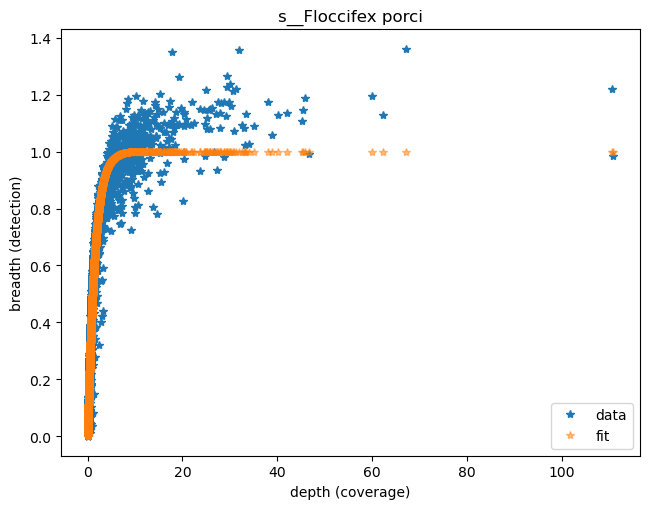

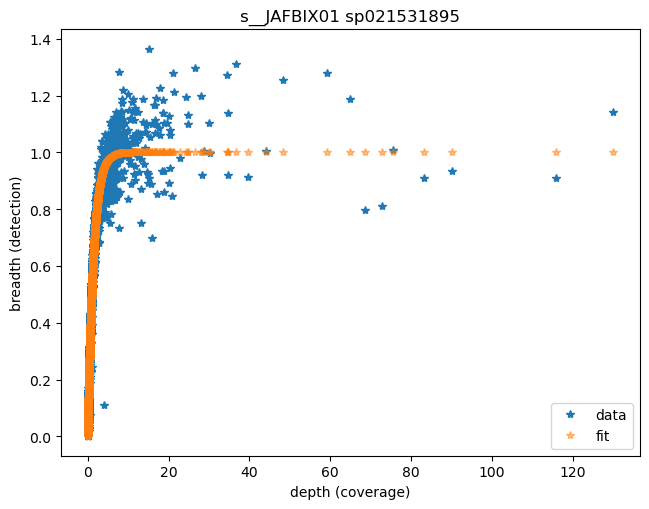

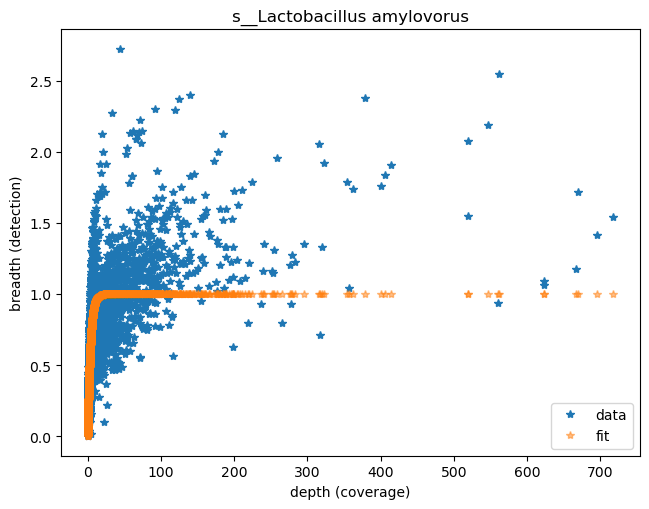

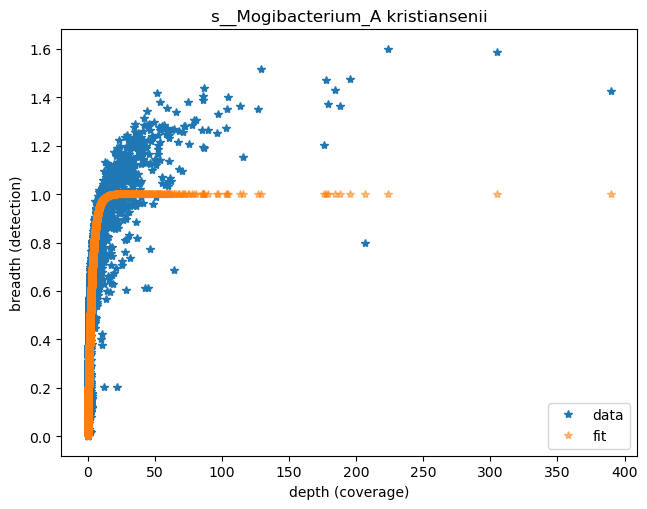

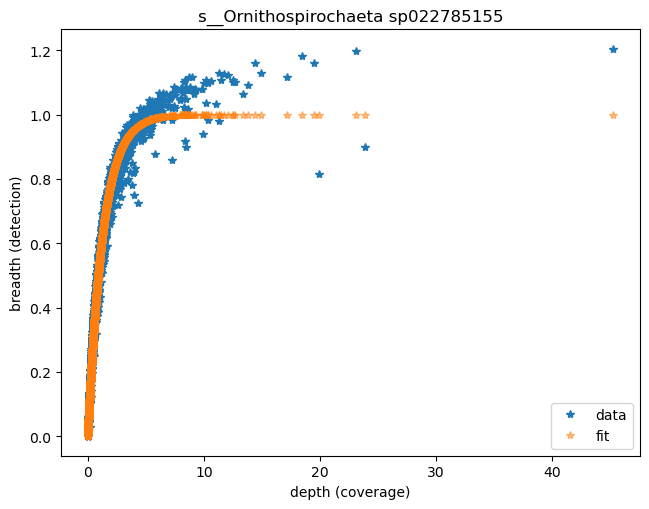

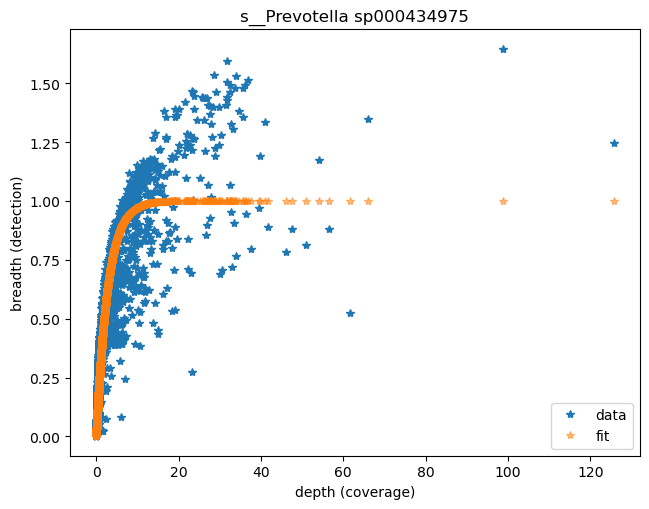

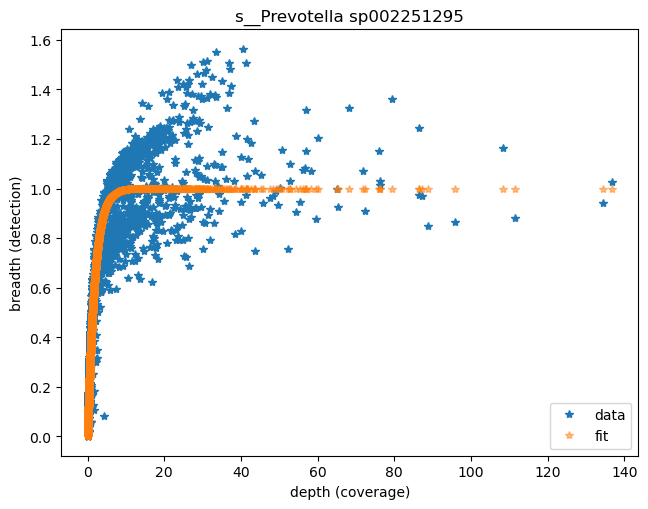

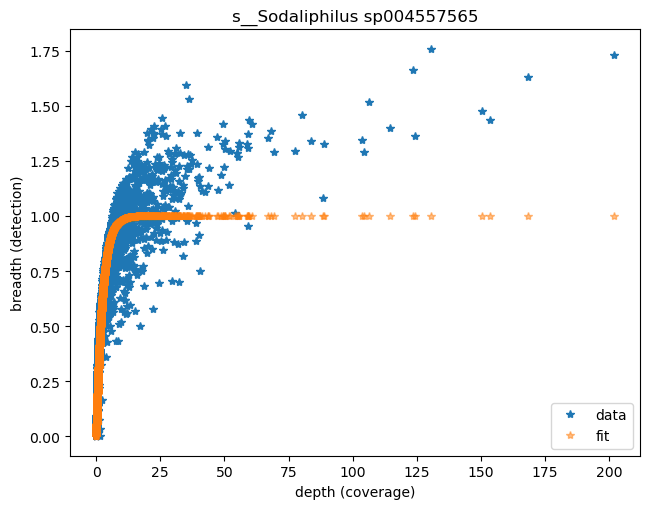

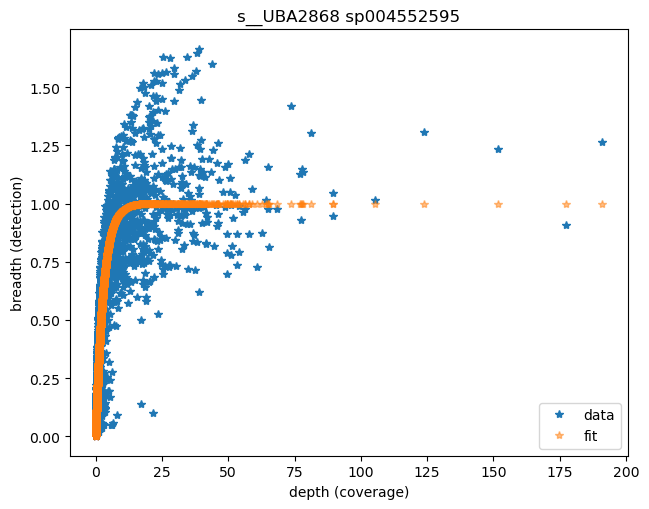

In [15]:
for name in NAMES:
    species_df = join_df.filter(pl.col("species") == name)

    plt.plot(species_df['fit_depth'], species_df['fit_breadth'], '*', label='data')
    plt.plot(species_df['fit_depth'], species_df['curve_breadth'], '*', alpha=0.5, label='fit')
    plt.tight_layout()
    plt.title(name)
    plt.xlabel('depth (coverage)')
    plt.ylabel('breadth (detection)')
    plt.legend(loc='lower right')

    #plt.xlim(0, 3)
    #plt.ylim(0, 1.5)
    plt.show()


## Zoom in a bit on the lower coverage ones (out to 3)

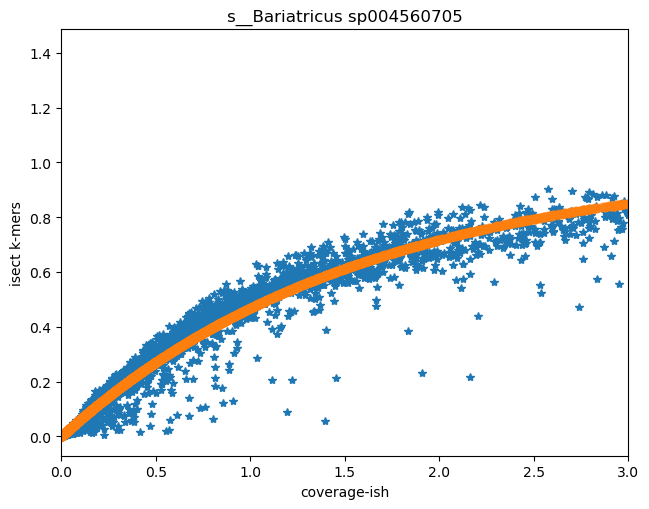

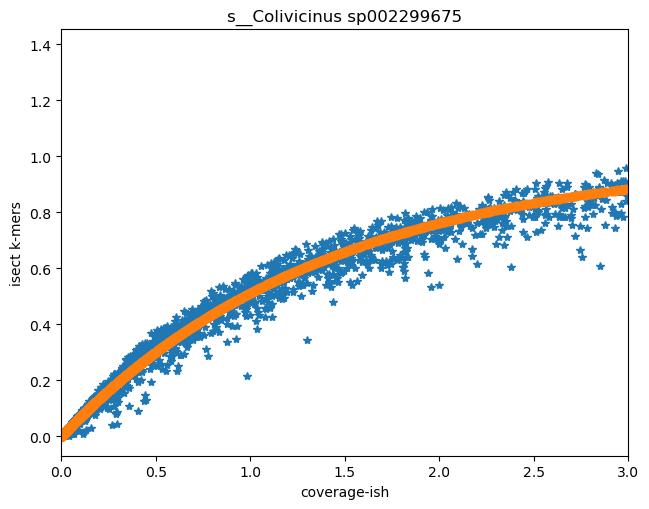

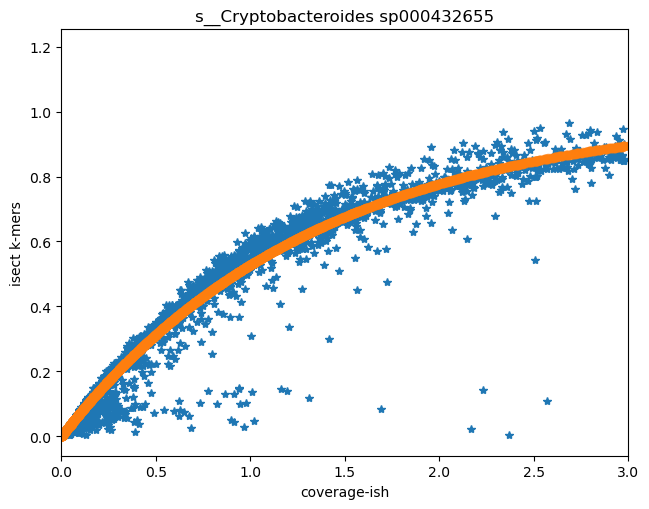

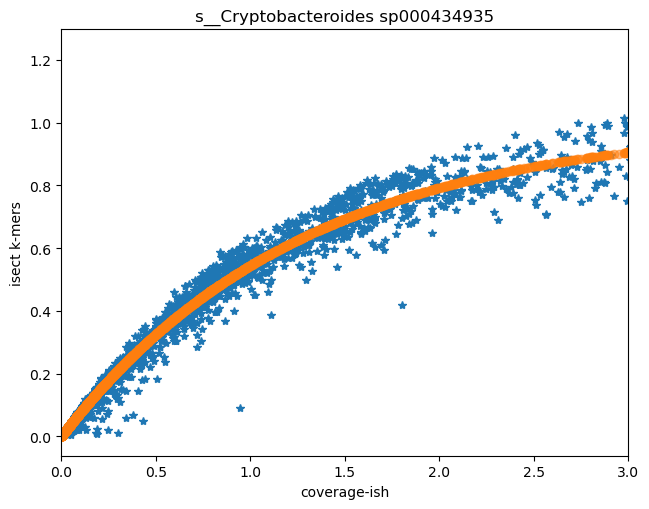

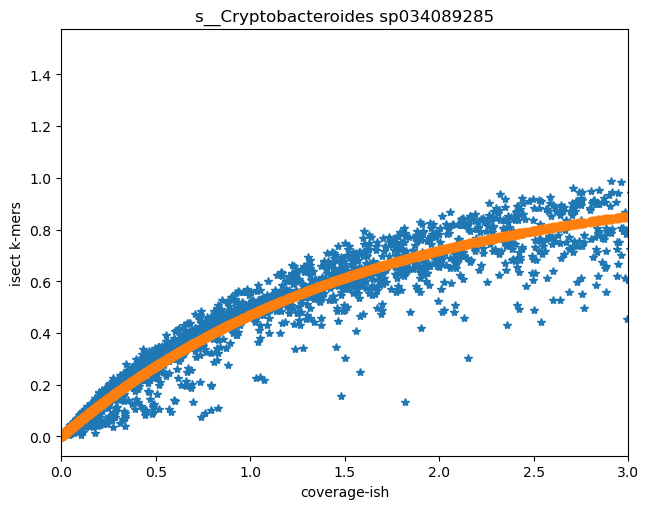

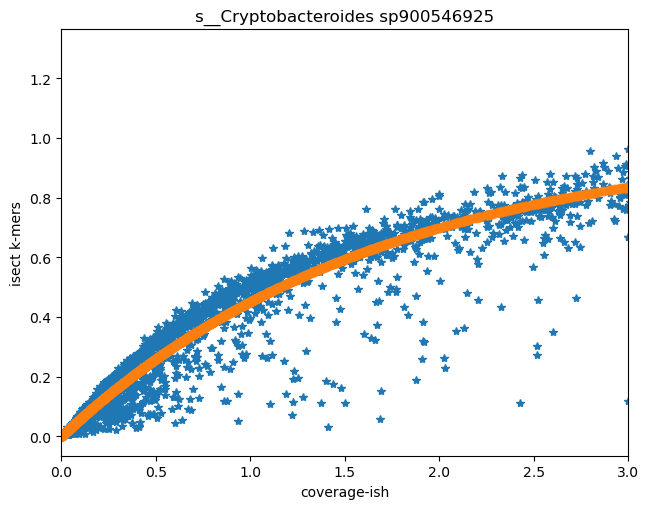

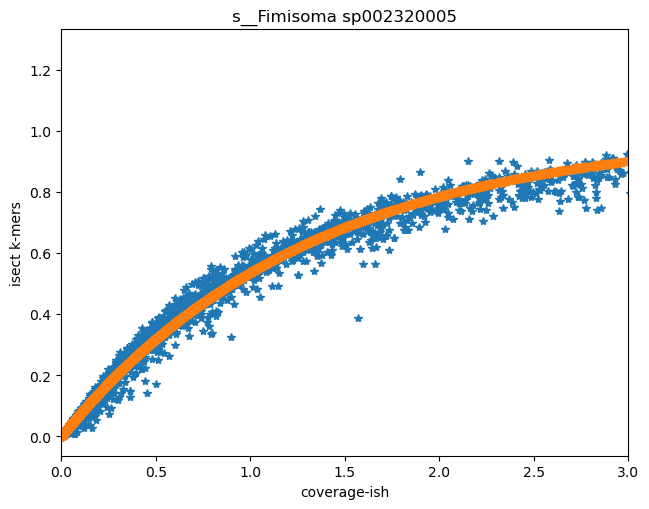

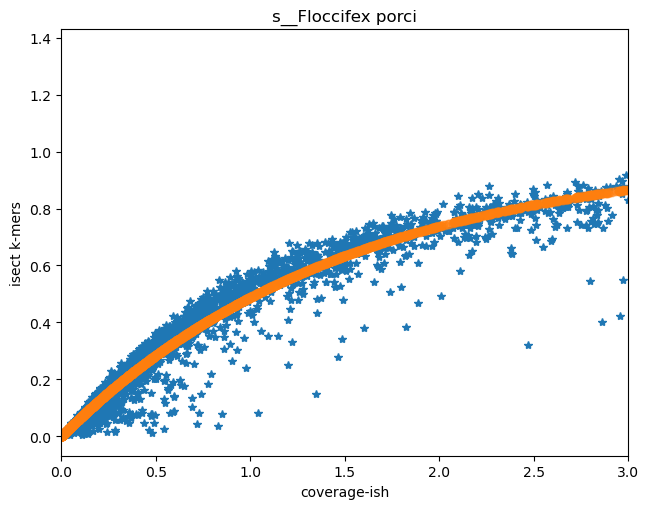

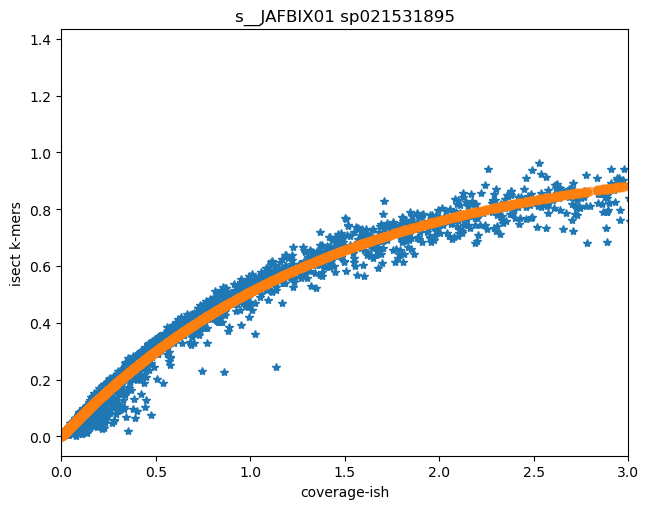

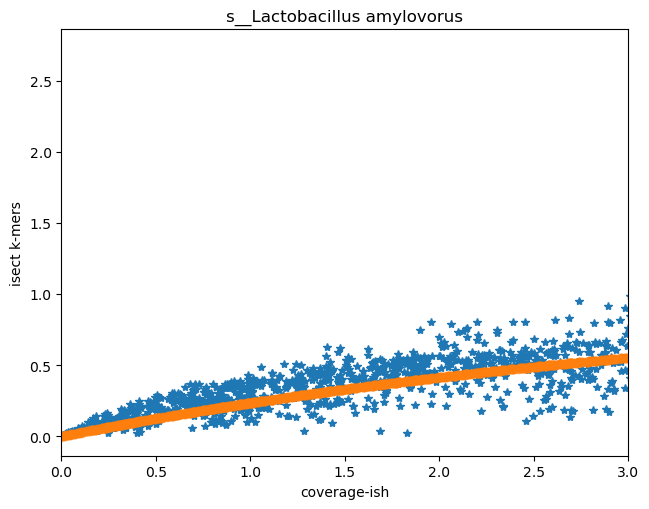

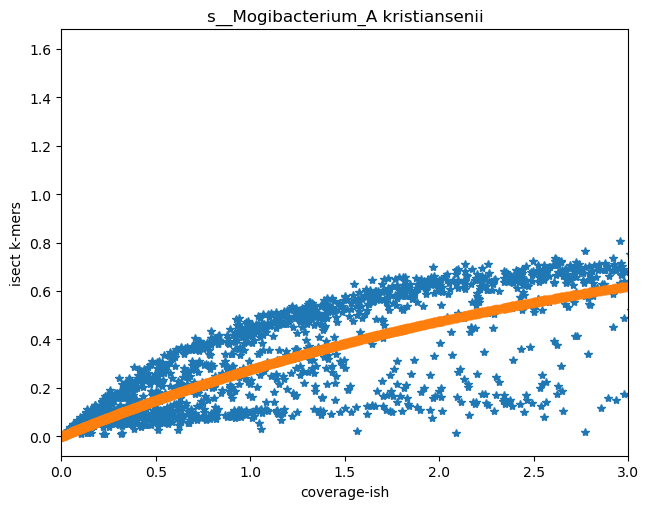

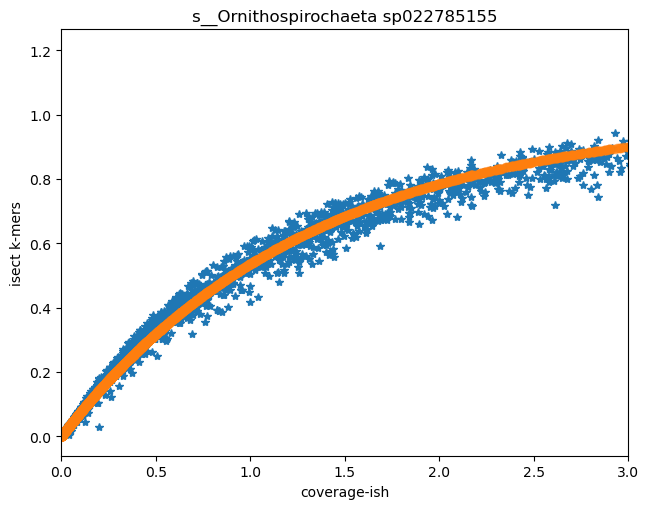

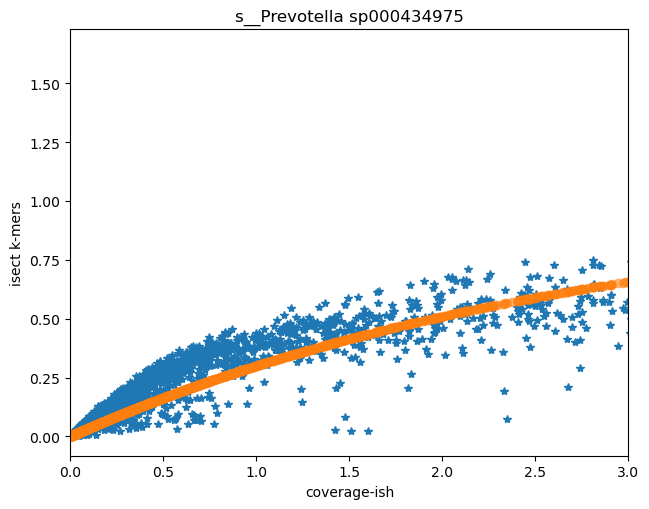

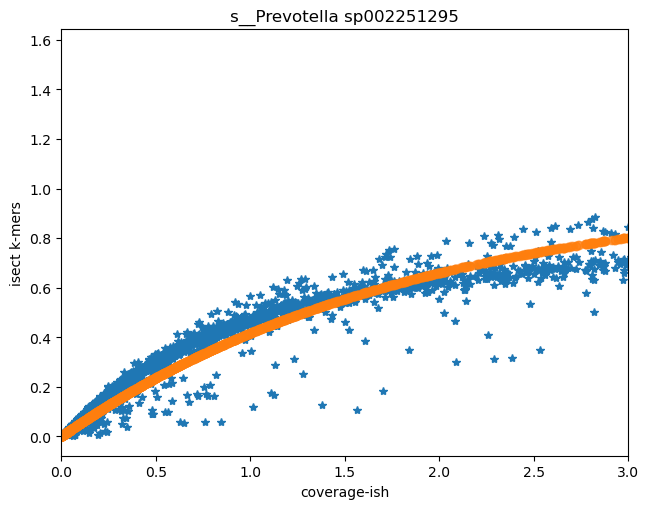

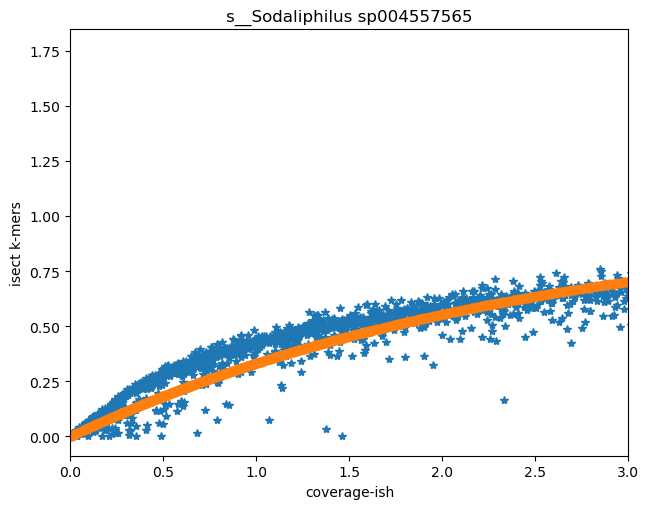

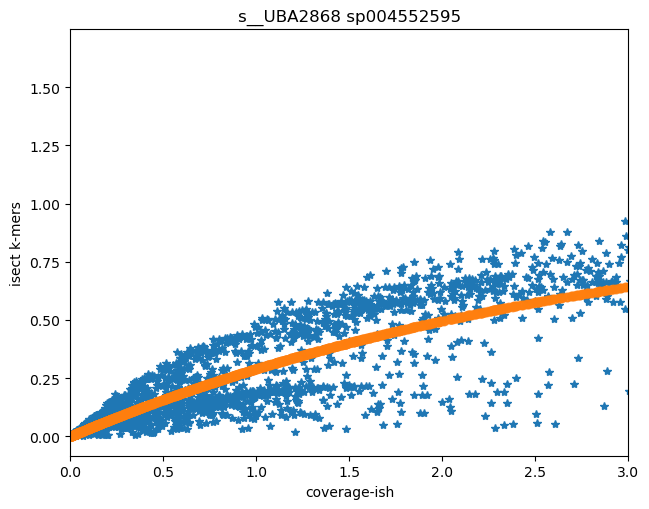

In [16]:
XLIM_MAX=3

for name in NAMES:
    species_df = join_df.filter(pl.col("species") == name)
    GSIZE, EXP, r2 = params_d[name]

    plt.plot(species_df['fit_depth'], species_df['fit_breadth'], '*')
    plt.plot(species_df['fit_depth'], species_df['curve_breadth'], 'o', alpha=0.5)

    plt.xlim(0, XLIM_MAX)    
    plt.tight_layout()
    plt.title(name)
    plt.xlabel('coverage-ish')
    plt.ylabel('isect k-mers')
    plt.show()


In [17]:
join_df

species,metag,intersect_bp,weighted_bp,fit_breadth,fit_depth,curve_breadth
str,str,i64,i64,f64,f64,f64
"""s__Bariatricus sp004560705""","""ERR3212028""",384000,708000,0.342105,0.630756,0.328791
"""s__Bariatricus sp004560705""","""ERR3211889""",474000,821000,0.422286,0.731428,0.37017
"""s__Bariatricus sp004560705""","""SRR8960468""",448000,880000,0.399123,0.783991,0.390751
"""s__Bariatricus sp004560705""","""SRR8960622""",1014000,5675000,0.903371,5.055851,0.959058
"""s__Bariatricus sp004560705""","""SRR11126389""",295000,428000,0.262815,0.381305,0.214164
…,…,…,…,…,…,…
"""s__UBA2868 sp004552595""","""SRR11125751""",144000,669000,0.0718,0.333573,0.1081
"""s__UBA2868 sp004552595""","""SRR11183692""",1484000,20458000,0.739944,10.200655,0.969754
"""s__UBA2868 sp004552595""","""ERR3211805""",423000,2616000,0.210914,1.304375,0.360676


In [18]:
join_df.write_csv('../outputs.isect/isect_kmers_coverage_fits.csv')

In [19]:
params_df.write_csv('../outputs.isect/isect_kmers_coverage_fitparams.csv')